# Figure 4 — CDK2/4/6 and clinical variants

Reads only `data/processed/` and `data/reference/`. Nothing here recomputes a
screen statistic; if a number looks wrong the fix belongs upstream.

| panel | content | from | status |
|---|---|---|---|
| a | Cross-drug resistance heatmap | `09_analysis_and_viz/logo_plots_CDK2_4_6_canonical.ipynb cell 29` | **figure** |
| b | Resistance hits per drug by gene | `09_analysis_and_viz/logo_plots_CDK2_4_6_canonical.ipynb cell 33` | **figure** |
| c | ChimeraX renders for figure 4c (2 images), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| d | ChimeraX renders for figure 4d (2 images), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| e | ChimeraX renders for figure 4e (2 images), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| f | CDK4 validation allele frequency | `09_analysis_and_viz/analysis.ipynb cell 137` | **figure** |
| g | T47D pre- and post-selection plot | `data/raw/collaborator_panels/T47D_MCF7/cdk_variant_T47D_plot_t0_tf.svg` | **figure** |
| i | T47D competition fold-change heatmap | `data/raw/collaborator_panels/T47D_MCF7/C010_T47D_comp_foldchange_heatmap_horizontal.svg` | published image |
| j | C014 | `data/raw/collaborator_panels/T47D_MCF7/20261011_C014.png` | published image |
| k | T47D %S phase, ABE-derived lines | `data/raw/collaborator_panels/T47D_cell_cycle` | **figure** |
| l | T47D %S phase, CBE-derived lines | `data/raw/collaborator_panels/T47D_cell_cycle` | **figure** |
| m | RNA-seq marker-gene panel, DMSO and palbociclib | `data/raw/collaborator_panels/T47D_MCF7/marker_gene_panel_DMSO_palbo_stacked.svg` | published image |
| n | Xenograft tumour volume, CDK6 | `11_in_vivo_analysis/invivo_xenograft_CDK6_palbociclib.ipynb cell 20` | **figure** |
| o | Xenograft Ki67, CDK6 | `11_in_vivo_analysis/invivo_xenograft_CDK6_palbociclib.ipynb cell 22` | **figure** |
| p | CDK6 clinical variants | `12_clinical_analysis/clinical.ipynb cells 19-23` | **figure** |

**figure** — this notebook regenerates both the source data and the panel.
**source data** — the table regenerates and is checked by `tests/`; the
plotting is still in the original notebook named above.
**not ported** — the plotting is not in this repository yet.
See `docs/COVERAGE.md` for the status of every panel.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(next(p for p in Path.cwd().resolve().parents
                            if (p / "src" / "cdkbe").is_dir()) / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cdkbe import paths, io, editing, lfc, plotting
from cdkbe.source_data import PANELS

plotting.use_style()
paths.ensure(paths.FIG_MAIN)

## Source data

The frames these panels plot.

In [2]:
for key in ["4a", "4b", "4c", "4d", "4e", "4f", "4g", "4k", "4l", "4n", "4o", "4p"]:
    result = PANELS[key]()
    frames = result if isinstance(result, dict) else {"": result}
    for name, df in frames.items():
        label = f"{key}/{name}" if name else key
        print(f"{label:<28} {len(df):>8,} rows x {len(df.columns)} cols")

4a                                 93 rows x 33 cols
4b                                 18 rows x 4 cols
4c                                 31 rows x 15 cols
4d                                 39 rows x 15 cols
4e                                 20 rows x 15 cols
4f                                 11 rows x 3 cols
4g                                  8 rows x 3 cols
4k/replicates                      18 rows x 9 cols
4k/means                            6 rows x 7 cols
4k/significance                     4 rows x 10 cols
4l/replicates                      18 rows x 9 cols
4l/means                            6 rows x 7 cols
4l/significance                     4 rows x 10 cols
4n                                 20 rows x 13 cols
4o                                 20 rows x 11 cols


4p/hits                             5 rows x 6 cols
4p/per_replicate_LFC               45 rows x 6 cols


## Panels

Each panel below is drawn from `data/processed/` and rendered inline, and also
written to `figures/main/`. The numbers printed on the in vivo panels are
checked against the manuscript in `tests/test_invivo_figures.py`.

In [3]:
from matplotlib.figure import Figure

from cdkbe.source_data import DRAWN
from cdkbe.source_data import invivo_figures as ivf

# Drawing functions predate this notebook and return four different shapes: a
# bare figure, (figure, source rows), a dict of either keyed by gene or by
# sub-panel, or -- for the in vivo cohorts -- a list of (figure, stats) pairs.
# `show` takes them all rather than each cell knowing which it is getting.
DRAW = {k: ("invivo" if k in ivf.FIGURES else "screen", v)
        for k, v in DRAWN.items()}


def show(fig, note=None):
    if note:
        print(note)
    display(fig)
    plt.close(fig)


def describe(obj):
    if isinstance(obj, dict):
        return ", ".join(f"{e}: {len(g):,} guides" for e, g in obj.items())
    return f"{len(obj):,} rows"


def draw(key):
    """Draw one panel, show it, and report what it is made of."""
    kind, fn = DRAW[key]
    result = fn(outdir=paths.FIG_MAIN)
    if kind == "invivo":
        for fig, stats in result:
            cols = [c for c in ["Cohort", "comparison", "group",
                                "n_WT", "n_mutant", "p_shown"] if c in stats.columns]
            display(stats[cols])
            show(fig)
        return
    if isinstance(result, Figure):
        show(result)
        return
    if isinstance(result, dict):              # one figure per gene or sub-panel
        for name, v in result.items():
            if isinstance(v, Figure):
                show(v, f"{key} {name}")
            else:
                fig, sub = v
                show(fig, f"{key} {name}: {describe(sub)}")
        return
    fig, obj = result
    if not isinstance(fig, Figure):           # a ChimeraX panel: rendered images
        print(describe(obj))
        display(fig)                          # tiled preview; see structures.Renders
        return
    show(fig, describe(obj))

### 4a — Cross-drug resistance heatmap

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


1 extra bytes in post.stringData array


... (6 outputs left out)

Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


4a CDK2: 20 rows


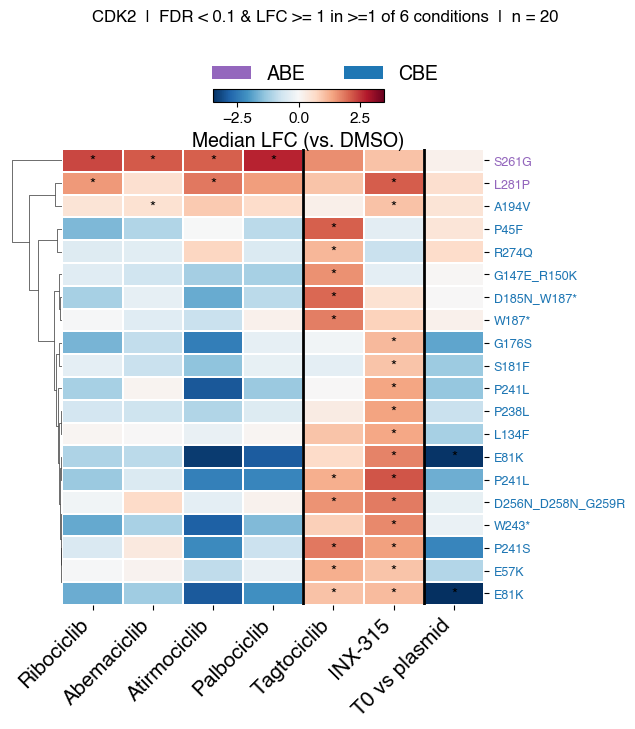

4a CDK4: 35 rows


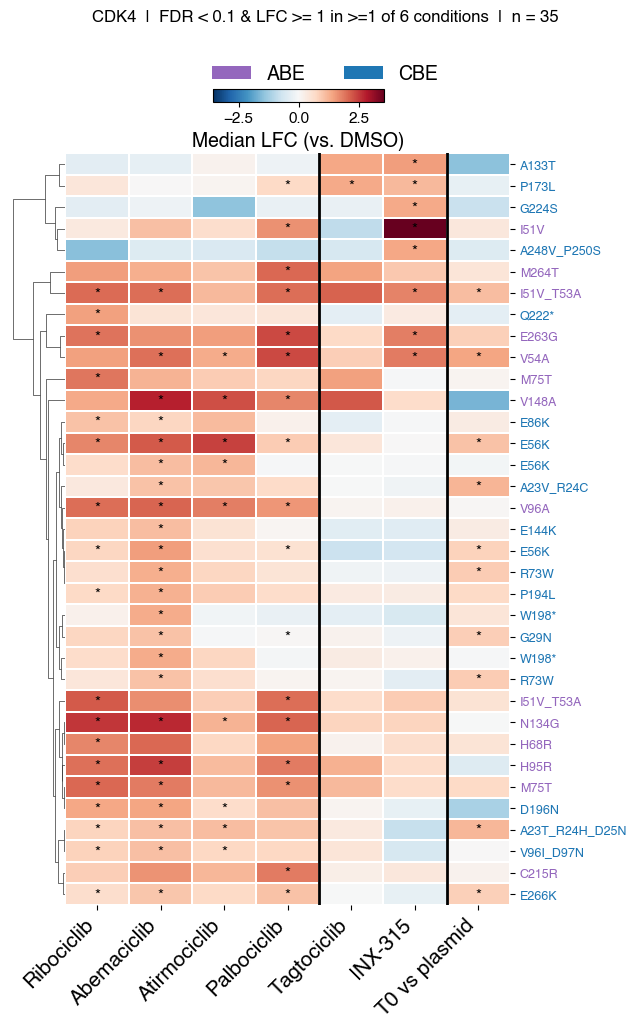

4a CDK6: 38 rows


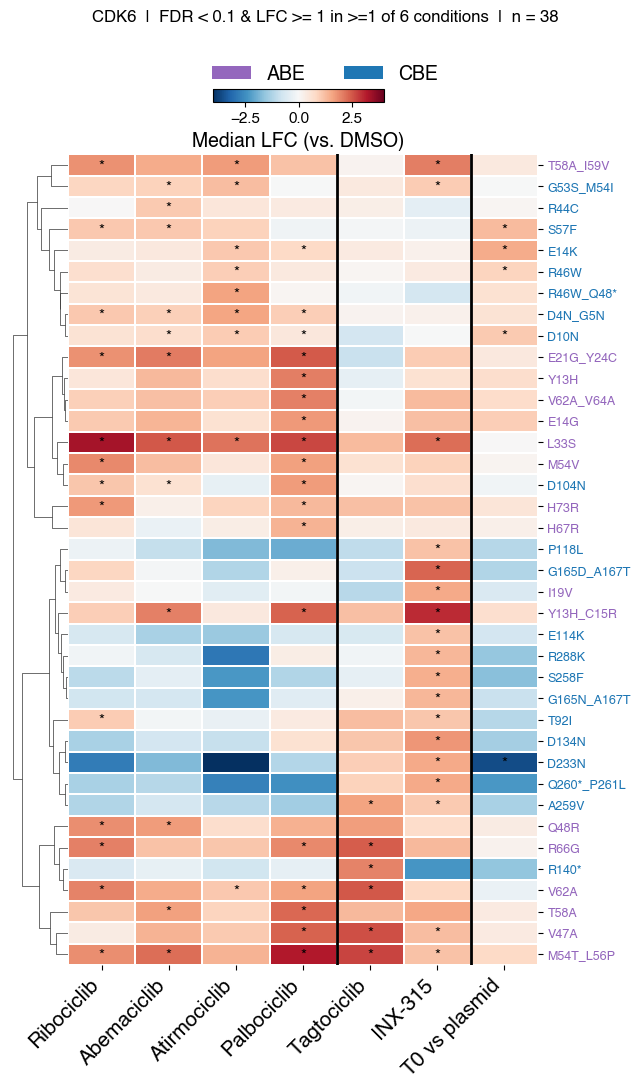

In [4]:
draw("4a")

### 4b — Resistance hits per drug by gene

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


18 rows


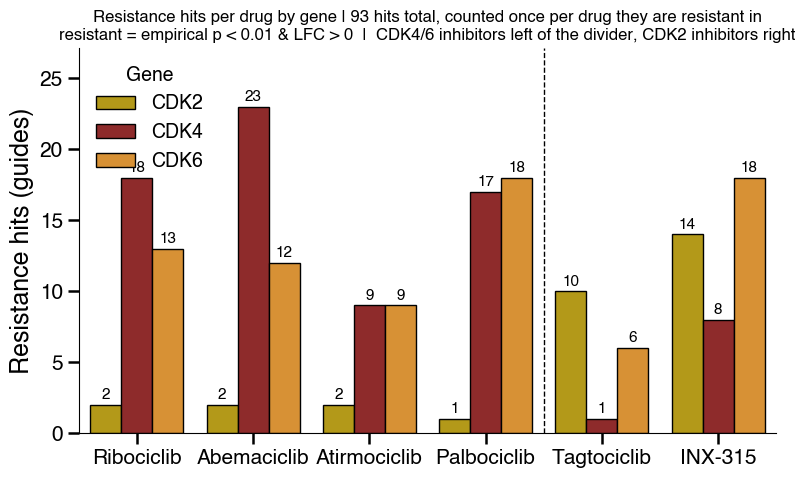

In [5]:
draw("4b")

### 4c — ChimeraX renders for figure 4c (2 images), with the residues marked

31 rows


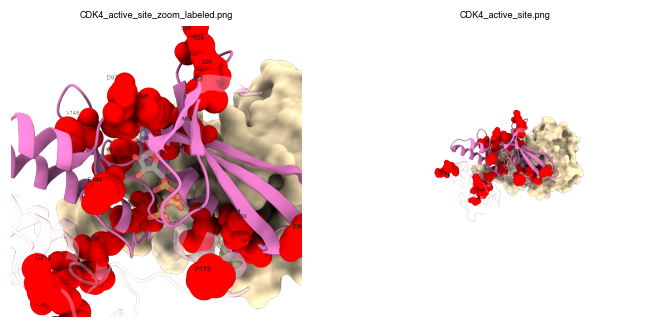

In [6]:
draw("4c")

### 4d — ChimeraX renders for figure 4d (2 images), with the residues marked

39 rows


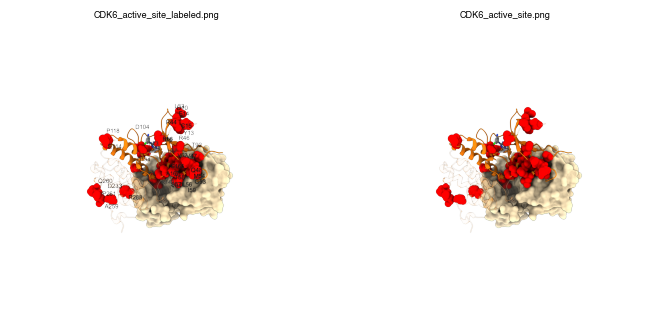

In [7]:
draw("4d")

### 4e — ChimeraX renders for figure 4e (2 images), with the residues marked

20 rows


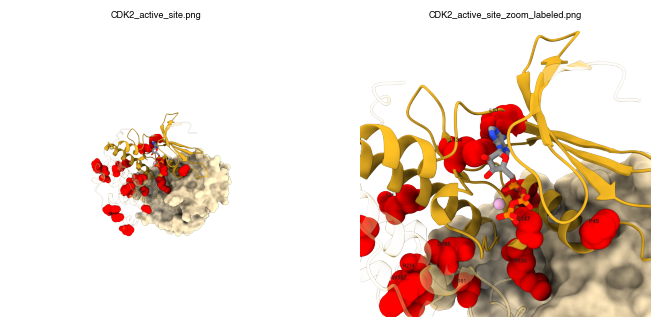

In [8]:
draw("4e")

### 4f — CDK4 validation allele frequency

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


11 rows


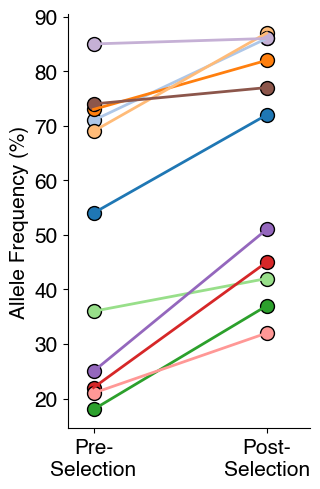

In [9]:
draw("4f")

### 4g — T47D pre- and post-selection plot

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


8 rows


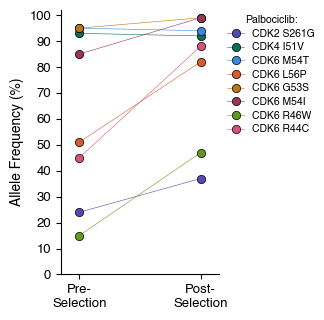

In [10]:
draw("4g")

### 4k — T47D %S phase, ABE-derived lines

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


4 rows


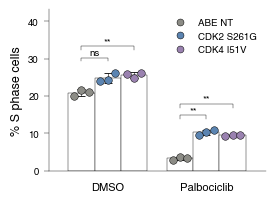

In [11]:
draw("4k")

### 4l — T47D %S phase, CBE-derived lines

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


4 rows


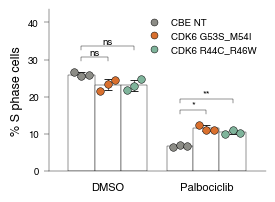

In [12]:
draw("4l")

### 4n — Xenograft tumour volume, CDK6

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


,Cohort,n_WT,n_mutant,p_shown
0,CDK6 R46W,5,5,0.435340
1,CDK6 R46W,5,5,0.339531
2,CDK6 R46W,5,5,0.024732
3,CDK6 R46W,5,5,0.285127


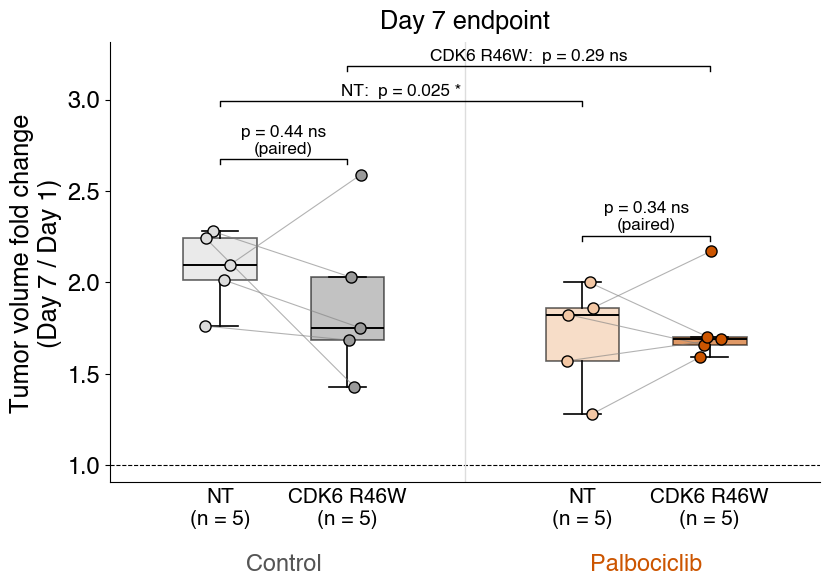

In [13]:
draw("4n")

### 4o — Xenograft Ki67, CDK6

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


,Cohort,n_WT,n_mutant,p_shown
0,CDK6 R46W,5,5,0.117422
1,CDK6 R46W,5,5,0.687436
2,CDK6 R46W,5,5,0.018156
3,CDK6 R46W,5,5,0.173270


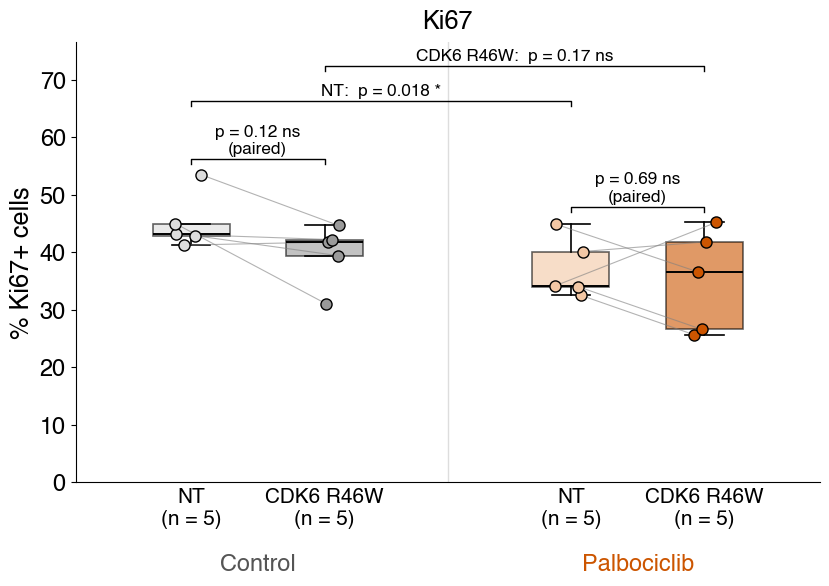

In [14]:
draw("4o")

### 4p — CDK6 clinical variants

Matplotlib is building the font cache; this may take a moment.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


5 rows


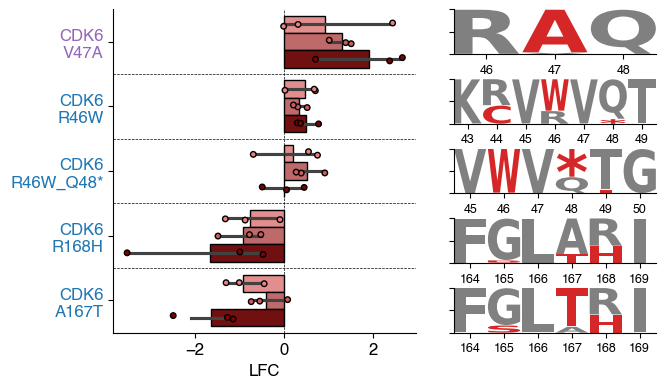

In [15]:
draw("4p")

## Included as published images

- **4i** — T47D competition fold-change heatmap
- **4j** — C014
- **4m** — RNA-seq marker-gene panel, DMSO and palbociclib

These panels are included as the images that were published, under
`data/raw/collaborator_panels/`, and are shown below. This repository does not
regenerate them.

In [16]:
from IPython.display import Image, SVG

4i: data/raw/collaborator_panels/T47D_MCF7/C010_T47D_comp_foldchange_heatmap_horizontal.svg


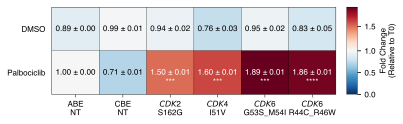

In [17]:
print("4i:", "data/raw/collaborator_panels/T47D_MCF7/C010_T47D_comp_foldchange_heatmap_horizontal.svg")
_p = paths.ROOT / "data/raw/collaborator_panels/T47D_MCF7/C010_T47D_comp_foldchange_heatmap_horizontal.svg"
display(SVG(filename=str(_p)) if _p.suffix == ".svg" else Image(filename=str(_p)))

4j: data/raw/collaborator_panels/T47D_MCF7/20261011_C014.png


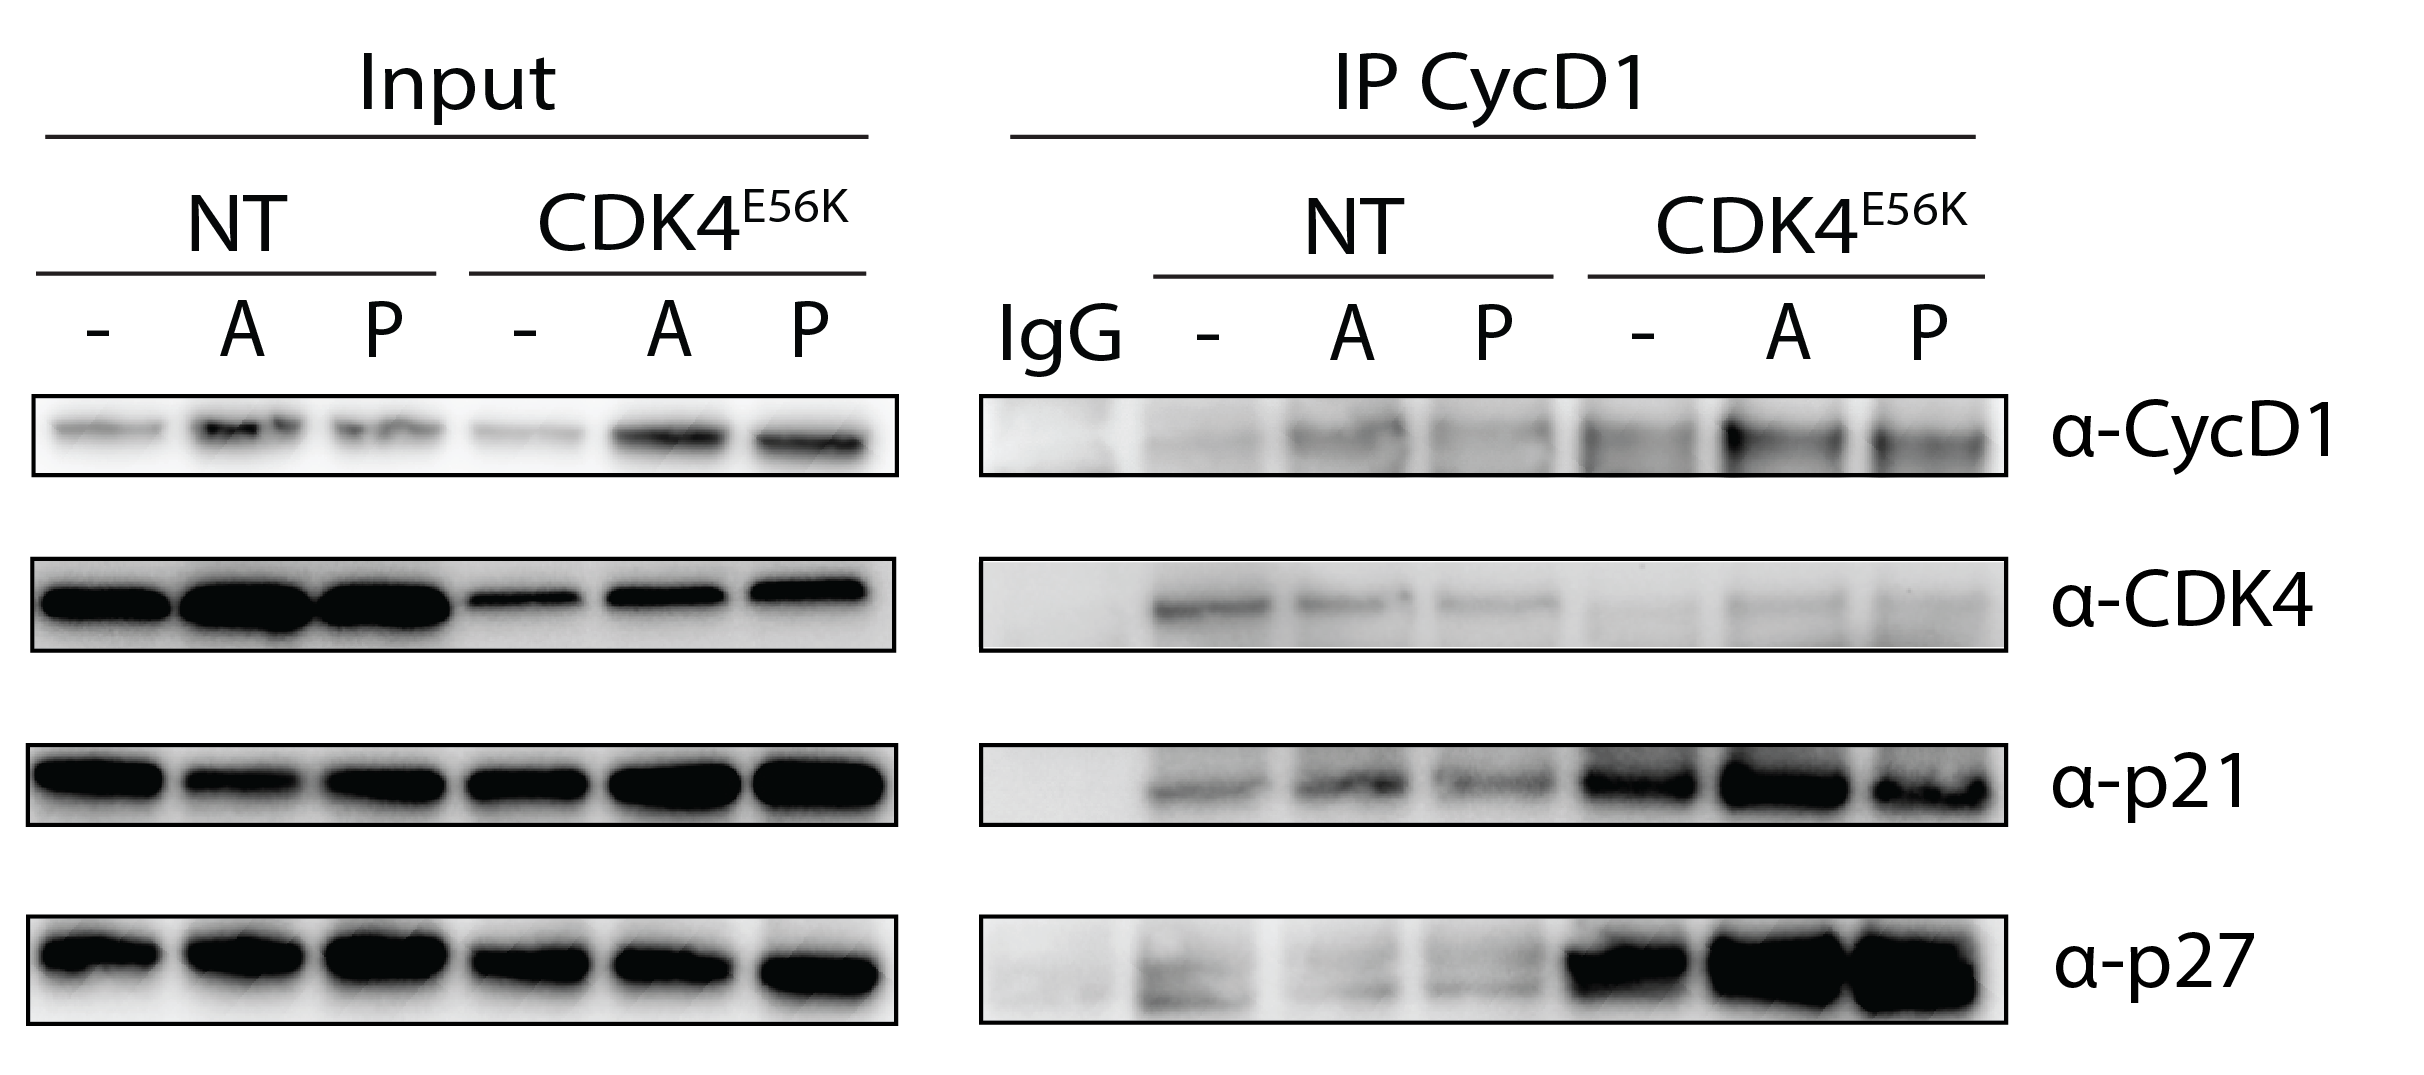

In [18]:
print("4j:", "data/raw/collaborator_panels/T47D_MCF7/20261011_C014.png")
_p = paths.ROOT / "data/raw/collaborator_panels/T47D_MCF7/20261011_C014.png"
display(SVG(filename=str(_p)) if _p.suffix == ".svg" else Image(filename=str(_p)))

4m: data/raw/collaborator_panels/T47D_MCF7/marker_gene_panel_DMSO_palbo_stacked.svg


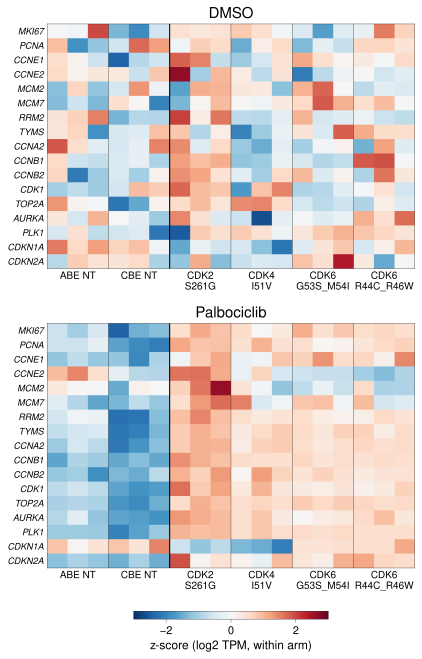

In [19]:
print("4m:", "data/raw/collaborator_panels/T47D_MCF7/marker_gene_panel_DMSO_palbo_stacked.svg")
_p = paths.ROOT / "data/raw/collaborator_panels/T47D_MCF7/marker_gene_panel_DMSO_palbo_stacked.svg"
display(SVG(filename=str(_p)) if _p.suffix == ".svg" else Image(filename=str(_p)))